## Modelling the duration of delays of TunisAir

This notebook contains the steps for developing a Machine Learning model to predict delays of flights based on a number of predictors. The calculations use as input the data cleaned by the steps summarized in a [previous notebook of this project](/04_data-cleaning.ipynb).

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
# Importing from .csv requires converting the dates to daytime in pandas
# Since duration calculations are already done, we only need to strip the UTC part


#df["STD_UTC"] = pd.to_datetime(df["STD_UTC"], format="%Y-%m-%d %H:%M:%S")
#df["STD"] = pd.to_datetime(df["STD"],utc=True, dayfirst=True, format= "%Y-%m-%d %H:%M:%S")

# import the pre-processed data
df = pd.read_csv('data/Train_cleaned.csv', parse_dates=["STD_UTC", "STA_UTC"])
# Create specific time blocks
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 22:
        return 'Evening'
    else:
        return 'Night'

df['time_of_day'] = df['hour'].apply(get_time_of_day)
df["STD_UTC"].head()


0   2016-08-19 03:00:00+00:00
1   2016-08-19 06:30:00+00:00
2   2016-08-19 09:35:00+00:00
3   2016-08-20 06:30:00+00:00
4   2016-08-20 09:35:00+00:00
Name: STD_UTC, dtype: datetime64[us, UTC]

### Train and test split

Given the sequential nature of this dataset, it is important to keep the order of records and not randomize the samples when creating splits in the data. In this way, the temporal structure of the time series is maintained. A gap of 200 flights was also included between partitions to reduce the effect of past of future data on a given partition.

A particular implementation of the cross-validation algorithm was devised to accommodate this training data split strategy and evaluate the models using the requested RMSE and two other informative metrics to compare regression models.

In [66]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import cross_validate

ts_cv = TimeSeriesSplit(
    n_splits=5,
    gap=200,
)

# define a function to evaluate the models
def evaluate(model, X, y, cv, model_prop=None, model_step=None):
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"],
        return_estimator=True,
    )
    if model_prop is not None:
        if model_step is not None:
            values = [
                getattr(m[model_step], model_prop) for m in cv_results["estimator"]
            ]
        else:
            values = [getattr(m, model_prop) for m in cv_results["estimator"]]
        print(f"Mean model.{model_prop} = {np.mean(values)}")
    mae = -cv_results["test_neg_mean_absolute_error"]
    rmse = -cv_results["test_neg_root_mean_squared_error"]
    rsquared = -cv_results["test_r2"]
    print(
        f"R-squared:     {rsquared.mean():.3f} +/- {rsquared.std():.3f}\n"
        f"Mean Absolute Error:     {mae.mean():.3f} +/- {mae.std():.3f}\n"
        f"Root Mean Squared Error: {rmse.mean():.3f} +/- {rmse.std():.3f}"
    )
    # To display the fitted estimator diagrams in the notebook.
    return cv_results["estimator"][0]

### This is a variation of the code to accommodate a transformer within the pipeline

In [67]:
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

def evaluate_trans(model, X, y, cv, model_prop=None, model_step=None):
    cv_results = cross_validate(
        model, X, y, cv=cv, 
        scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"], 
        return_estimator=True
    )
    
    if model_prop is not None:
        values = []
        for m in cv_results["estimator"]:
            current = m
            
            # 1. If the outer model is the TransformedTargetRegressor wrapper
            if isinstance(current, TransformedTargetRegressor):
                current = current.regressor_
                
            # 2. If we are dealing with a Pipeline, extract the specific step
            if isinstance(current, Pipeline) and model_step is not None:
                # If the step name 'ridgecv' isn't found directly, look inside a wrapped step
                if model_step in current.named_steps:
                    current = current.named_steps[model_step]
                elif 'transformedtargetregressor' in current.named_steps:
                    step = current.named_steps['transformedtargetregressor']
                    if isinstance(step, TransformedTargetRegressor):
                        current = step.regressor_
            
            # 3. If the step itself was wrapped inside TransformedTargetRegressor
            if isinstance(current, TransformedTargetRegressor):
                current = current.regressor_
                
            values.append(getattr(current, model_prop))
            
        print(f"Mean model.{model_prop} = {np.mean(values):.5f}")

    rsquared = -cv_results["test_r2"]    
    mae = -cv_results["test_neg_mean_absolute_error"]
    rmse = -cv_results["test_neg_root_mean_squared_error"]
    print(f"R-squared: {rsquared.mean():.3f} +/- {rsquared.std():.3f}")
    print(f"Mean Absolute Error: {mae.mean():.3f} +/- {mae.std():.3f}")
    print(f"Root Mean Squared Error: {rmse.mean():.3f} +/- {rmse.std():.3f}")

### Definition of predictors and target subsets
After exploratory data analyses (see separate notebook) we identified a number of predictors to be included in our modelling approach. We also explore the correlations among numerical predictors and the target. Luckily, the numerical features are not strongly correlated but this might be obscured by any periodic cycles in the data.

<Axes: >

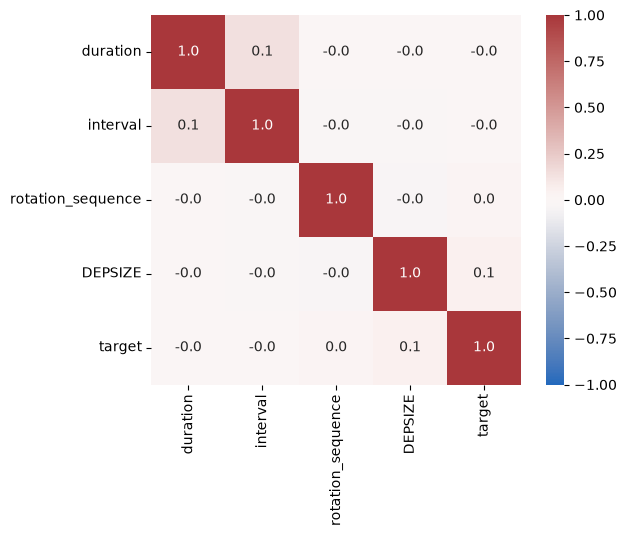

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
cor_data = df[["duration", "interval","rotation_sequence", "DEPSIZE", "target"]]

cor_data = cor_data.dropna()
plt.rcParams.update({'font.size': 10})
sns.heatmap(cor_data.corr(),vmin=-1.0, vmax=1.0, cmap="vlag", square=True,annot=True,fmt='.1f')


In [33]:
# Defining target and predictors
df_small = df[["duration", "interval", "rotation_sequence", "DEPSIZE", "year", 
                     "month","weekday", "hour",
                    "weekend", "time_of_day", "DEPSTN", "ARRSTN", "target"]].dropna()

df_small = df_small[df_small['target'] <= 600] # removing extreme delays. Delays of more than 10 hours are extremely rare and hinder the model
X = df_small.drop("target", axis=1)
y = df_small["target"]

## Modelling
We start by modelling the delays using a ridge regression. This linear regression technique, commonly used to analyze data that suffers from multicollinearity, adds a L2 penalty (the squared magnitude of coefficients multiplied by a lambda/alpha hyperparameter) to the ordinary least squares cost function. This shrinks coefficients toward zero, reducing variance and preventing overfitting. Larger values of alpha specify stronger regularization and the variant we used (RidgeCV) estimates the optimal alpha parameter by cross-validation.

In [34]:
# Accessory function to log-transform the target
from sklearn.linear_model import RidgeCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

#1. Define target transformation functions
def func(x):
    return np.log1p(x)
def inverse_func(x):
    return np.expm1(x)
alphas = np.logspace(-6, 6, 25)
regr = TransformedTargetRegressor(regressor=RidgeCV(alphas = alphas),
                                  func=func,
                                  inverse_func=inverse_func,
                                  check_inverse=False)

In [35]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline

categorical_columns=["year", "month", "weekend", "time_of_day", "DEPSTN", "ARRSTN"]
numeric_columns=["duration", "interval", "rotation_sequence", "DEPSIZE"]
one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
transformer = RobustScaler()
alphas = np.logspace(-6, 6, 25)
naive_linear_pipeline =  make_pipeline(
    ColumnTransformer(
        transformers=[
            ("categorical", one_hot_encoder, categorical_columns),
            ("numeric", transformer, numeric_columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ),
   regr
)


naive_linear_pipeline.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_featur

In [36]:
evaluate_trans(
    naive_linear_pipeline, X, y, cv=ts_cv, model_prop="alpha_", model_step="ridgecv")


Mean model.alpha_ = 2.72982
R-squared: 0.077 +/- 0.051
Mean Absolute Error: 37.559 +/- 9.071
Root Mean Squared Error: 80.955 +/- 13.599


In [37]:
from sklearn.metrics import r2_score
y_pred1 =  naive_linear_pipeline.predict(X)       # predicted values
linear_score = r2_score(y, y_pred1)     # compare real vs predicted
print(linear_score) 

-0.05948494977871799


In [38]:
from sklearn.ensemble import HistGradientBoostingRegressor
gbrt_categorical_columns=["year", "month", "weekend", "time_of_day", "DEPSTN", "ARRSTN"]
gbrt = HistGradientBoostingRegressor(categorical_features=gbrt_categorical_columns, 
                                     random_state=42)
evaluate(gbrt, X, y, cv=ts_cv, model_prop="n_iter_")

Mean model.n_iter_ = 92.0
R-squared:     -0.147 +/- 0.189
Mean Absolute Error:     42.190 +/- 2.037
Root Mean Squared Error: 70.354 +/- 5.436


,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.","['year', 'month', ...]"
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If intera

In [39]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.compose import make_column_selector

categorical_columns=["year", "month", "weekend", "time_of_day"]
numeric_columns=["duration", "interval", "rotation_sequence", "DEPSIZE"]
tt_columns=["DEPSTN", "ARRSTN"]
one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
target_encoder = TargetEncoder(target_type="continuous")
transformer = RobustScaler()

gbrt = HistGradientBoostingRegressor(
                            n_iter_no_change = 12,
                            max_leaf_nodes = 20,
                            max_iter = 300,
                            learning_rate = 0.083,
                            l2_regularization = 0.00025,
                            interaction_cst = 'pairwise',
                            early_stopping= False,
                            random_state=42
)
HGBRT_pipeline =  make_pipeline(
    ColumnTransformer(
        transformers=[
            ("categorical", one_hot_encoder, categorical_columns),
            ("numeric", transformer, numeric_columns),
            ("target_encoded", target_encoder, tt_columns)
        ],
        #make_column_selector(dtype_include="category"),
        remainder="drop",
        verbose_feature_names_out=False,
    ),
   gbrt
).set_output(transform="pandas")


HGBRT_pipeline.fit(X,y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.ge

In [40]:
y_pred2 =  HGBRT_pipeline.predict(X)       # predicted values
HGBRT_score = r2_score(y, y_pred2)     # compare real vs predicted
print(HGBRT_score) 

0.2511947724042526


In [41]:
#iterations = str(HGBRT_pipeline[-1].n_iter_)
evaluate(HGBRT_pipeline, X, y, cv=ts_cv)

R-squared:     -0.115 +/- 0.187
Mean Absolute Error:     43.426 +/- 1.691
Root Mean Squared Error: 71.712 +/- 5.669


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.ge

### Hyper parameter optimization of the HGBRT
The HGBRT model is the best performing model in terms of RMSE, so we attempt to optimize the hyperparameters of this model using a randomized grid search.

In [42]:
import numpy as np
from scipy.stats import loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


param_grid = {
    'early_stopping': [True, False],
    'learning_rate': loguniform(0.01, 1),
    'interaction_cst': ['pairwise', 'no_interactions'],
    'l2_regularization': np.logspace(-6, 0, 6),
    'max_iter': [3, 10, 30, 100, 300, 1000],
    'max_leaf_nodes': [2, 5, 10, 20, 50, 100],
    'n_iter_no_change': np.arange(5,30),
    }


rs = RandomizedSearchCV(
    HistGradientBoostingRegressor(categorical_features=gbrt_categorical_columns, 
                                     random_state=42), 
    param_grid,
    scoring='neg_mean_squared_error',
    cv = ts_cv,
    verbose=0,
    n_jobs=-1,
    random_state=42,
)
#.drop(['time_of_day','DEPSTN','ARRSTN'], axis=1)
rs.fit(X,y)
# Get params
# Returning best score after GridSearch and the best parameter combination
print("                Best score:", rs.best_score_.round(4))
print("Best parameter combination:", rs.best_params_)
RSearch_best = rs.best_estimator_
# Best parameter combination: {'early_stopping': False, 'interaction_cst': 'pairwise',
#  'l2_regularization': np.float64(0.00025118864315095795), 'learning_rate': np.float64(0.0828891686688514), 
# 'max_iter': 300, 'max_leaf_nodes': 20, 'n_iter_no_change': np.int64(12)}


                Best score: -5065.7351
Best parameter combination: {'early_stopping': False, 'interaction_cst': 'pairwise', 'l2_regularization': np.float64(0.00025118864315095795), 'learning_rate': np.float64(0.0828891686688514), 'max_iter': 300, 'max_leaf_nodes': 20, 'n_iter_no_change': np.int64(12)}


### Evaluate performance of the HGBRT model with optimized parameters
We now use the best performing parameters of the randomized grid search to implement and test the HGBRT model. Interestingly, this model alone performs better that when included in a pipeline with feature engineering. This is thus our winning model.

In [43]:
#categorical_columns = categorical_columns.append(['DEPSTN'])
ogbrt = HistGradientBoostingRegressor(categorical_features=gbrt_categorical_columns,
                                    n_iter_no_change = 12,
                                    max_leaf_nodes = 20,
                                    max_iter = 300,
                                    learning_rate = 0.083,
                                    l2_regularization = 0.00025,
                                    interaction_cst = 'pairwise',
                                    early_stopping= False,
                                    random_state=42)
evaluate(ogbrt, X, y, cv=ts_cv, model_prop="n_iter_")

Mean model.n_iter_ = 300.0
R-squared:     -0.120 +/- 0.223
Mean Absolute Error:     43.410 +/- 1.604
Root Mean Squared Error: 71.160 +/- 4.642


,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.083
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",300
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.00025
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.","['year', 'month', ...]"
,"interaction_cst interaction_cst: {""pairwise"", ""no_interactions""} or sequence of lists/tuples/sets of int, default=NoneSpecify interaction constraints, the sets of features which caninteract with each other in child node splits.Each item specifies the set of feature indices that are allowedto interact with each other. If there are more features thanspecified in these constraints, they are treated as if they werespecified as an additional set.The strings ""pairwise"" and ""no_interactions"" are shorthands forallowing only pairwise or no interactions, respectively.For instance, with 5 features in total, `interaction_cst=[{0, 1}]`is equivalent to `interaction_cst=[{0, 1}, {2, 3, 4}]`,and specifies that each branch of a tree will either only spliton features 0 and 1 or only split on features 2, 3 and 4.See :ref:`this example<ice-vs-pdp>` on how to use `interaction_cst`... versionadded:: 1.2",'pairwise'
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"n_iter_no_change n_iter_no_change: int, default=10Used to determine when to ""early stop"". The fitting process isstopped when none of the last ``n_iter_no_change`` scores are betterthan the ``n_iter_no_change - 1`` -th-to-last one, up to sometolerance. Only used if early stopping is performed.",12
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss lo

In [44]:
from sklearn.metrics import r2_score
ogbrt.fit(X,y)
y_pred3 =  ogbrt.predict(X)       # predicted values
ogbrt_score = r2_score(y, y_pred3)     # compare real vs predicted
print(ogbrt_score) 

0.2967799154161732


### Using spline transformers to fit cyclic features
We implement a variation of the ridge regression model with a preprocessing step where we add different splines to model cyclic features like month and week days. This feature engineering step can help the model to predict cyclic peaks of delays.

In [45]:
from sklearn.preprocessing import SplineTransformer


def periodic_spline_transformer(period, n_splines=None, degree=3):
    if n_splines is None:
        n_splines = period
    n_knots = n_splines + 1  # periodic and include_bias is True
    return SplineTransformer(
        degree=degree,
        n_knots=n_knots,
        knots=np.linspace(0, period, n_knots).reshape(n_knots, 1),
        extrapolation="periodic",
        include_bias=True,
    )

### Model implementation and testing
We use the engineered periodic splines along with categorical and continuous features in a pipeline that includes a log-transformation of the target.  

In [46]:
regr = TransformedTargetRegressor(regressor=RidgeCV(alphas = alphas),
                                  func=func,
                                  inverse_func=inverse_func,
                                  check_inverse=False)

cyclic_spline_transformer = ColumnTransformer(
    transformers=[
        ("categorical", one_hot_encoder, ['DEPSTN', 'year', "time_of_day"]),
        ("cyclic_month", periodic_spline_transformer(12, n_splines=6), ["month"]),
        ("cyclic_weekday", periodic_spline_transformer(7, n_splines=3), ["weekday"]),
        #("cyclic_hour", periodic_spline_transformer(24, n_splines=12), ["hour"]),
        ("continuous", RobustScaler(), ["duration", "rotation_sequence"]) #"duration", 
    ],
    remainder="drop",
    verbose_feature_names_out=False
    )

cyclic_spline_linear_pipeline = make_pipeline(
    cyclic_spline_transformer,
    regr,
)

evaluate(cyclic_spline_linear_pipeline, X, y, cv=ts_cv)

R-squared:     0.091 +/- 0.054
Mean Absolute Error:     38.292 +/- 8.125
Root Mean Squared Error: 81.472 +/- 13.704


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('cyclic_month', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.

### Adding interaction features to the previous model

We now add another feature engineering step to model the second-order interactions between "weekend" and "time-of-day factors". We apply the polynomial transformer in a separate step to restrict the interactions to these two features.

In [47]:
from sklearn.preprocessing import StandardScaler
reduced_cyclic_spline_transformer = ColumnTransformer(
    transformers=[
        ("categorical", one_hot_encoder, ['year']),
        ("cyclic_month", periodic_spline_transformer(12, n_splines=6), ['month']),
        ("cyclic_weekday", periodic_spline_transformer(7, n_splines=3), ['weekday']),
        #("cyclic_hour", periodic_spline_transformer(24, n_splines=8), ["hour"]),
        ("continuous", StandardScaler(), ['duration'])
    ],
    remainder="drop",
    verbose_feature_names_out=False
    )

In [48]:
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import PolynomialFeatures,FunctionTransformer, MinMaxScaler
tt_columns=["DEPSTN", "ARRSTN"]
target_encoder = TargetEncoder(target_type="continuous", shuffle=False)
interactions = make_pipeline(
    ColumnTransformer([
        ("weekend", FunctionTransformer(
                    lambda x: x == "True", feature_names_out="one-to-one"), ["weekend"]),
        ("time_of_day", one_hot_encoder, ['time_of_day']),
        ("target_encoded", target_encoder, tt_columns)
        ],
        verbose_feature_names_out=False,
        remainder="drop",
    ),
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=True),
)

In [49]:
regr = TransformedTargetRegressor(regressor=RidgeCV(alphas = alphas),
                                  func=func,
                                  inverse_func=inverse_func,
                                  check_inverse=False)
cyclic_spline_interactions_pipeline = make_pipeline(
    FeatureUnion(
        [
            ("marginal", reduced_cyclic_spline_transformer),
            ("interactions", interactions),
        ],
        verbose_feature_names_out=True,
    ).set_output(transform="pandas"),
    RidgeCV(alphas=alphas),
)
evaluate(cyclic_spline_interactions_pipeline, X, y, cv=ts_cv)

/Users/magc/neuefische_course/repositories/ds-ml-project-flight_delay_prediction/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/magc/neuefische_course/repositories/ds-ml-project-flight_delay_prediction/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/magc/neuefische_course/repositories/ds-ml-project-flight_delay_prediction/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarnin

R-squared:     0.003 +/- 0.143
Mean Absolute Error:     47.590 +/- 2.325
Root Mean Squared Error: 76.921 +/- 7.827


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('featureunion', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('marginal', ...), ('interactions', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


### Hurdle regression ensemble

We herein implemented a two-stage ensemble or hurdle regression. It is composed of two models: the first model predicts the occurrence of delays treating the target as binary (0: target >0, 1: target > 0), the second model uses these results and makes a quantitative prediction of the data subset where a target > 0 is predicted. 

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PolynomialFeatures, RobustScaler

target_encoder = TargetEncoder(target_type="continuous")
preprocessor = ColumnTransformer([
    ("categorical", one_hot_encoder, 
                          ["weekend", "year", "month", "hour"]),
    ("numeric", transformer, ["duration", "interval", "DEPSIZE"]),
    
    ],
    remainder="drop",
    
    )
   
preprocessor.fit(X, y)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

In [51]:
interactions = make_pipeline(
    ColumnTransformer([
        ("weekend", FunctionTransformer(
                    lambda x: x == "True", feature_names_out="one-to-one"), ["weekend"]),
        ("time_of_day", one_hot_encoder, ['time_of_day']),
        ("target_encoded", target_encoder, ["DEPSTN", "ARRSTN", "AC"])
        ],
        verbose_feature_names_out=False,
        remainder="drop",
    ),
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=True),
)

In [52]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler,MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted


# 2. Define the custom Hurdle Model (same as before)
class HurdleRegression(BaseEstimator, RegressorMixin):
    def __init__(self, classifier=None, regressor=None):
        self.classifier = classifier if classifier is not None else LogisticRegression()
        self.regressor = regressor if regressor is not None else LinearRegression()

    def fit(self, X, y):
        X, y = check_X_y(X, y)
        y_binary = (y > 0).astype(int)
        self.classifier.fit(X, y_binary)
        
        nonzero_mask = y > 0
        if np.sum(nonzero_mask) > 0:
            self.regressor.fit(X[nonzero_mask], y[nonzero_mask])
        
        self.is_fitted_ = True
        return self

    def predict(self, X):
        check_is_fitted(self, 'is_fitted_')
        X = check_array(X)
        
        zero_preds = self.classifier.predict(X)
        final_preds = np.zeros(X.shape[0])  # Ensured length matches rows
        
        nonzero_mask = zero_preds == 1
        if np.sum(nonzero_mask) > 0:
            final_preds[nonzero_mask] = self.regressor.predict(X[nonzero_mask])
            final_preds[final_preds < 0] = 0  # Force non-negative predictions
            
        return final_preds


# 2. Build the scikit-learn Pipeline
hurdle_pipeline = Pipeline([
    ('preprocessing', preprocessor),                 # Step 1: Preprocess features
    ('hurdle_model', HurdleRegression(            # Step 2: Custom two-step model
        classifier=LogisticRegression(max_iter=5000),
        regressor=gbrt
    ))
])

# 4. Train and predict using the Pipeline
evaluate(hurdle_pipeline, X, y, cv=ts_cv)

R-squared:     0.086 +/- 0.429
Mean Absolute Error:     52.660 +/- 4.101
Root Mean Squared Error: 77.557 +/- 2.569


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('hurdle_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['duration','interval','rotation_sequence',...,'time_of_day','DEPSTN', 'ARRSTN']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed th

### Plotting the best model residuals

We first calculate the predicted values for all our candidate models.

In [53]:
all_splits = list(ts_cv.split(X, y))
train_0, test_0 = all_splits[0]
last_hours = slice(-6800, -6600)
#sample_weights = np.where(y.iloc[train_0] > 80, 2.5, 1.0)

naive_linear_pipeline.fit(X.iloc[train_0], y.iloc[train_0])
naive_linear_predictions = naive_linear_pipeline.predict(X.iloc[test_0])

HGBRT_pipeline.fit(X.iloc[train_0], y.iloc[train_0])#, histgradientboostingregressor__sample_weight = sample_weights)
HGBRT_pipeline_predictions = np.clip(HGBRT_pipeline.predict(X.iloc[test_0]), a_min=0, a_max=None)

ogbrt.fit(X.iloc[train_0], y.iloc[train_0])#, histgradientboostingregressor__sample_weight = sample_weights)
oHGBRT_predictions = np.clip(ogbrt.predict(X.iloc[test_0]), a_min=0, a_max=None)

cyclic_spline_linear_pipeline.fit(X.iloc[train_0], y.iloc[train_0])
cyclic_spline_predictions = np.clip(cyclic_spline_linear_pipeline.predict(X.iloc[test_0]),
                                    a_min=0, a_max=None)


#hurdle_pipeline.fit(X.iloc[train_0], y.iloc[train_0])
#hurdle_predictions = np.clip(hurdle_pipeline.predict(X.iloc[test_0]),
#                             a_min=0, a_max=None)


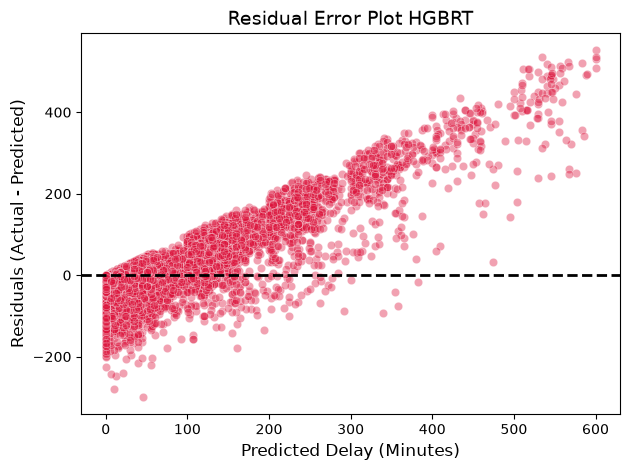

In [54]:
# Plot 2: Residuals vs Predicted Delays
import seaborn as sns
import matplotlib.pyplot as plt
cyresiduals = y.iloc[test_0] - oHGBRT_predictions
ax2 = sns.scatterplot(x=y.iloc[test_0], y=cyresiduals, alpha=0.4, color="crimson")
ax2.axhline(y=0, color="black", linestyle="--", linewidth=2)
ax2.set_title("Residual Error Plot HGBRT", fontsize=14)
ax2.set_xlabel("Predicted Delay (Minutes)", fontsize=12)
ax2.set_ylabel("Residuals (Actual - Predicted)", fontsize=12)

plt.tight_layout()
plt.show()

In [55]:
df.iloc[train_0][last_hours].STA_UTC.min()

Timestamp('2017-07-08 20:05:00+0000', tz='UTC')

### Plotting the model predictions

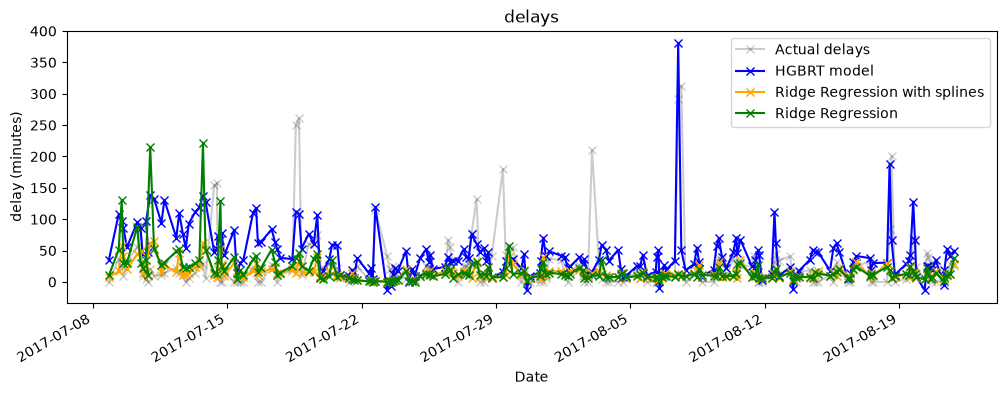

In [56]:
ogbrt.fit(X.iloc[train_0], y.iloc[train_0])
oHGBRT_predictions = ogbrt.predict(X.iloc[test_0])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.iloc[train_0][last_hours].STA_UTC, y.iloc[test_0].values[last_hours],
    "x-", alpha=0.2, label="Actual delays", color="black")
ax.plot(df.iloc[train_0][last_hours].STA_UTC, oHGBRT_predictions[last_hours],
    "x-", label="HGBRT model", color="blue")
ax.plot(df.iloc[train_0][last_hours].STA_UTC, cyclic_spline_predictions[last_hours],
    "x-", label="Ridge Regression with splines", color="orange")
ax.plot(df.iloc[train_0][last_hours].STA_UTC, naive_linear_predictions[last_hours], 
    "x-", label="Ridge Regression", color="green")

_ = ax.legend()
_ = ax.set(
    title="delays",
    xticks=pd.date_range(start="2017-07-08", end="2017-08-21", freq="7D"),
    xlabel="Date",
    ylabel="delay (minutes)",
)
fig.autofmt_xdate()
plt.show()

In [57]:
# Summary of model metrics
rmse = pd.DataFrame()
rmse["model"] = ["ridge_regression","ridge_regression_splines","HGBRT"]
rmse["RMSE"] = [80.06,76.93,71.50]
rmse["r2"] = [0.04, 0.00, 0.12]
rmse["sd"] = [13.01,7.827, 3.82]
rmse

,model,RMSE,r2,sd
0,ridge_regression,80.06,0.04,13.010
1,ridge_regression_splines,76.93,0.00,7.827
2,HGBRT,71.50,0.12,3.820


Text(0, 0.5, 'RMSE (min.)')

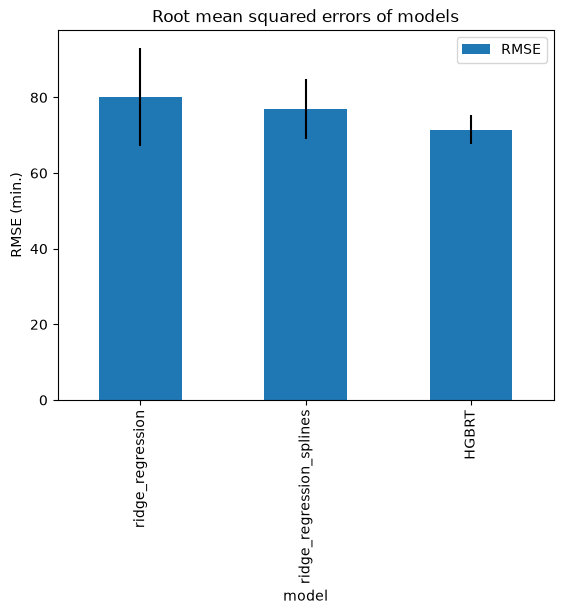

In [58]:

ax = rmse.plot.bar(x='model', 
                y="RMSE",
                yerr="sd")
ax.set_title("Root mean squared errors of models")
ax.set_ylabel("RMSE (min.)")


### Estimating feature importance in predicting delays
we used a permuted importance to estimate the decrease in RMSE when removing one feature at a time.

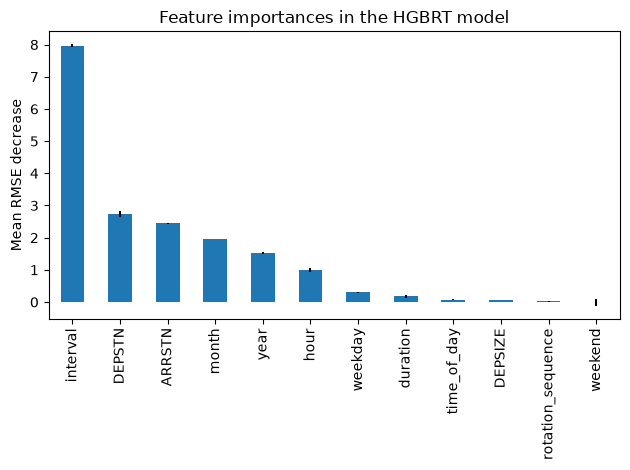

In [59]:
from sklearn.inspection import permutation_importance
test_arr = np.concatenate([x[1] for x in all_splits]) # recovering all 5 test partition indexes
raw_importances = permutation_importance(
    ogbrt, X.iloc[test_arr], y.iloc[test_arr], scoring= "neg_root_mean_squared_error", n_repeats=10, random_state=42, n_jobs=-1
) 
feature_names = X.columns #[f"feature {i}" for i in range(X.shape[1])]
HGBRT_importances = pd.Series(raw_importances.importances_mean, index=feature_names).sort_values(ascending=False)

#oHGBRT_importances = pd.Series(ogbrt.feature_importances_, index=X.iloc[train_0].columns)
#oHGBRT_importances_sorted_idx = np.argsort(ogbrt.feature_importances_)

fig, ax = plt.subplots()
HGBRT_importances.plot.bar(yerr=raw_importances.importances_std, ax=ax)
ax.set_title("Feature importances in the HGBRT model")
ax.set_ylabel("Mean RMSE decrease")
fig.tight_layout()
plt.show()


### Airports with most delays

In [62]:
DEP_delays = df.query('target > 30')[['DEPSTN','target']].groupby(by='DEPSTN').count()
top_DEP_delays = DEP_delays.sort_values(by='target',ascending=False).head(5)

df_plot = df[df['DEPSTN'].isin(list(top_DEP_delays.index))]

Text(0.5, 0.98, 'Top five airports in nr. of delays')

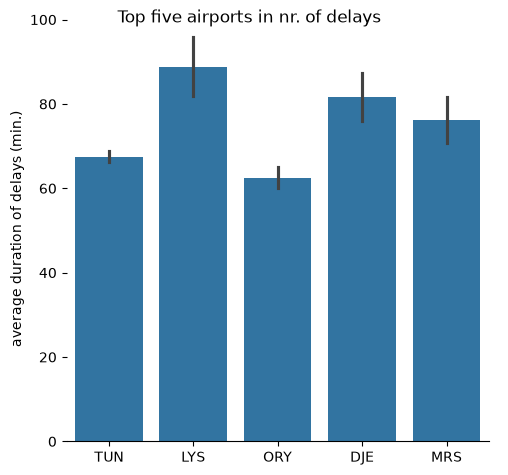

In [63]:

p = sns.catplot(
    data=df_plot.query('target > 0'), kind="bar",
    x="DEPSTN", y="target",# hue="sex",
    #errorbar="sd", #palette="dark", alpha=.6, height=6
)
p.despine(left=True)
p.set_axis_labels("", "average duration of delays (min.)")
p.fig.suptitle("Top five airports in nr. of delays")

# Save the Final Model

In [71]:
import joblib

joblib.dump(
    ogbrt,
    "models/final_hgbrt_model.pkl"
)

['models/final_hgbrt_model.pkl']